# Q-Learning Aproximado em um Labirinto com Armadilhas

## Integrantes

- **Caroline Nunes Araujo** — GitHub: [@Carol-Nunes](https://github.com/Carol-Nunes)
- **Gabriel Ciriaco de Carvalho** — GitHub: [@Gabriel-Ciriaco](https://github.com/Gabriel-Ciriaco)
- **João Gabriel de Morais Bezerra** — GitHub: [@joaobezcerra](https://github.com/joaobezcerra)

## Objetivo

Implementar um jogo de labirinto com caminhos alternativos e armadilhas
e desenvolver um agente capaz de aprender a alcançar a saída utilizando
Q-learning com aproximação linear. Analisar a influência da taxa de
aprendizado (alpha) e da quantidade de episódios no desempenho do agente,
considerando diferentes sementes aleatórias.

## Regras do ambiente

O jogo utiliza um labirinto fixo de 7 linhas e 9 colunas.
O agente começa na posição (1, 1) e deve alcançar a saída em (1, 7).
As coordenadas seguem o formato (linha, coluna), começando em zero.

### Símbolos do mapa

| Símbolo | Significado |
|---------|-------------|
| `#` | Parede |
| `.` | Caminho livre |
| `S` | Posição inicial |
| `E` | Saída |
| `T` | Armadilha |

### Movimentos e recompensas

O agente pode se mover para cima, baixo, esquerda ou direita,
uma célula por ação.

| Resultado da ação | Recompensa | Comportamento |
|------------------|------------|---------------|
| Movimento para caminho livre ou início | -1 | Avança para a célula |
| Tentativa de atravessar parede ou limite do mapa | -3 | Permanece na posição atual |
| Entrada em armadilha | -10 | Avança e continua o episódio |
| Chegada à saída | +30 | Avança e encerra o episódio |

Cada ação recebe apenas uma das recompensas acima.
As armadilhas permanecem no mapa após a passagem do agente.


### Baixando as bibliotecas

In [1]:
%pip install matplotlib numpy
%pip install pandas 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Importando as bibliotecas

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 

In [3]:
# Função que calcula a posição candidata. 
# Ela recebe a posição atual e a ação e, 
# a partir disso, calcula a posição candidata. 
def calcular_posicao_candidata(posicao_atual, acao):

    linha = posicao_atual[0]
    coluna = posicao_atual[1]

    if acao == "cima":

        return (linha - 1, coluna)

    if acao == "baixo":

        return (linha + 1, coluna)

    if acao == "direita":

        return (linha, coluna + 1)

    if acao == "esquerda":

        return (linha, coluna - 1)

    return posicao_atual # Se o agente recebe uma ação inválida, ele fica parado.

In [4]:
# Função que recebe a posição candidata e o mapa do labirinto e 
# verifica se a posição está dentro dos limites do mapa. 
def posicao_eh_valida(posicao_candidata, mapa_labirinto):

    qtd_linhas_mapa = len(mapa_labirinto)
    qtd_colunas_mapa = len(mapa_labirinto[0])

    linha = posicao_candidata[0]
    coluna = posicao_candidata[1]

    if ((0 <= linha < qtd_linhas_mapa) and (0 <= coluna < qtd_colunas_mapa)):

        return True

    return False 

# Função que recebe a posição candidata e o mapa do labirinto e 
# verifica se a posição é uma parede. 
def posicao_eh_parede(posicao_candidata, mapa_labirinto):

    linha = posicao_candidata[0]
    coluna = posicao_candidata[1]

    if mapa_labirinto[linha][coluna] == "#":

        return True 

    return False

# Função que recebe a posição candidata e o mapa do labirinto e 
# verifica se a posição é uma armadilha. 
def posicao_eh_armadilha(posicao_candidata, mapa_labirinto):

    linha = posicao_candidata[0]
    coluna = posicao_candidata[1]

    if mapa_labirinto[linha][coluna] == "T":

        return True 

    return False

# Função que recebe a posição candidata e o mapa do labirinto e 
# verifica se a posição é uma parede. 
def posicao_eh_saida(posicao_candidata, mapa_labirinto):

    linha = posicao_candidata[0]
    coluna = posicao_candidata[1]

    if mapa_labirinto[linha][coluna] == "E":

        return True 

    return False


In [5]:
# Função que recebe a posição atual, a ação e o mapa do labirinto e 
# devolve uma tupla que informa qual será a nova posição do agente, 
# qual será a recompensa dele para a ação e informa se ele chegou à saída.
def movimentar(posicao_atual, acao, mapa_labirinto):

    posicao_candidata = calcular_posicao_candidata(posicao_atual, acao)

    # A posição candidata está além dos limites do mapa, logo 
    # o agente não se mexe, tem penalidade de -3 e não chegou à saída. 
    if not posicao_eh_valida(posicao_candidata, mapa_labirinto):

        return (posicao_atual, -3, False)

    # A posição candidata é uma parede , logo o agente não se 
    # mexe, tem penalidade de -3 e não chegou à saída.
    if posicao_eh_parede(posicao_candidata, mapa_labirinto):

        return (posicao_atual, -3, False)

    # A posição candidata é uma armadilha, logo o agente 
    # avança, tem penalidade de -10 e não chegou à saída.
    if posicao_eh_armadilha(posicao_candidata, mapa_labirinto):

        return (posicao_candidata, -10, False)

    # A posição candidata é a saída, logo o agente 
    # avança para ela, tem recompensa de +30 e chegou à saída.
    if posicao_eh_saida(posicao_candidata, mapa_labirinto):

        return (posicao_candidata, +30, True)

    # É um simples movimento em uma célula livre. 
    else:

        return (posicao_candidata, -1, False)

### Características utilizadas

| Característica | Descrição |
|----------------|-----------|
| Bias | Valor constante igual a 1, que permite aprender um valor básico para Q |
| Colisão | Vale 1 se a ação tentar atravessar uma parede ou sair do mapa; caso contrário, vale 0 |
| Armadilha | Vale 1 se a ação entrar em uma armadilha; caso contrário, vale 0 |
| Saída | Vale 1 se a ação alcançar a saída; caso contrário, vale 0 |
| Distância normalizada | Distância Manhattan da posição resultante até a saída, dividida por 14 |
| 12 bases gaussianas | Representam a proximidade da posição resultante a pontos de referência distribuídos pelo mapa |

In [6]:
# Função que recebe a posição atual, ação, mapa e posição de saída 
# e extrai as caracterpisticas. 
def extrair_caracteristicas(posicao_atual, acao, mapa_labirinto, posicao_saida):

    posicao_candidata = calcular_posicao_candidata(posicao_atual, acao)

    colisao = 0.0
    armadilha = 0.0
    saida = 0.0 

    # Em caso de colisão, a posição resultante permance igual à posição atual. 
    if not posicao_eh_valida(posicao_candidata, mapa_labirinto) or posicao_eh_parede(posicao_candidata, mapa_labirinto):

        posicao_resultante = posicao_atual

        colisao = 1.0 

    else:

        # Se não houve colisão, a posição resultante é aquela que o agente 
        # ficaria após executar a ação. 
        posicao_resultante = posicao_candidata

        if posicao_eh_armadilha(posicao_candidata, mapa_labirinto):

            armadilha = 1.0 

        if posicao_eh_saida(posicao_candidata, mapa_labirinto):

            saida = 1.0 

    # Vamos calcular a distância normalizada até a saída usando a distância
    # de Manhattan, pois se trata de uma grade. 

    distancia_absoluta = abs(posicao_resultante[0] - posicao_saida[0]) + abs(posicao_resultante[1] - posicao_saida[1])

    max_distancia_possivel = (len(mapa_labirinto) - 1) + (len(mapa_labirinto[0]) - 1)

    distancia_normalizada = distancia_absoluta / max_distancia_possivel

    bias = 1.0 # Ajuda nos cálculos da IA 

    caracteristicas_lista = [bias, colisao, armadilha, saida, distancia_normalizada]

    # Só a distância até a saída não mostra em qual corredor o agente está.
    # Por isso, usamos bases gaussianas para representar a proximidade a
    # alguns pontos do mapa. Assim, ele pode aprender a avaliar regiões
    # diferentes, mesmo quando elas estão à mesma distância da saída.

    # Definindo 12 pontos de referência para calcularmos as bases gaussianas. 
    linhas_referencia = [1, 3, 5]
    colunas_referencia = [1, 3, 5, 7]

    linha_res = posicao_resultante[0]
    coluna_res = posicao_resultante[1]

    # Calculando as bases gaussianas. 
    for linha in linhas_referencia:

        for coluna in colunas_referencia:

            distancia_quadrada = (linha_res - linha) ** 2 + (coluna_res - coluna) ** 2
            
            proximidade = np.exp(-distancia_quadrada / 4)

            caracteristicas_lista.append(proximidade)

    vetor_caracteristicas = np.array(caracteristicas_lista, dtype=np.float64)

    return vetor_caracteristicas

In [7]:
# Função que calula o q_valor aproximado realizando o produto 
# escalar entre os pesos e as caracteristicas. 
def calcular_q(pesos, vetor_caracteristicas):

    return np.dot(pesos, vetor_caracteristicas)

### Escolher ação 

Durante o treinamento, a estratégia epsilon-greedy alterna entre
escolher ações aleatórias e escolher uma ação com o maior Q estimado.
Empates são resolvidos por sorteio.

Na avaliação, epsilon é zero e os pesos permanecem fixos.
O agente continua sorteando entre ações empatadas, quando houver.

In [8]:
# Define qual ação o agente vai tomar usando a estratégia epsilon-greedy.
# Tem uma chance (epsilon) de testar direções aleatórias para explorar o labirinto,
# senão ele escolhe a ação com maior valor estimado de Q.
def escolher_acao(posicao_atual, posicao_saida, mapa_labirinto, epsilon, acoes_disponiveis, gerador_aleatorio, pesos):

    # Sortei um número entre 0 e 1 
    if gerador_aleatorio.random() < epsilon:

        # O agente vai explorar. Ele escolhe uma das ações com igual probabilidade. 
        return gerador_aleatorio.choice(acoes_disponiveis)

    # O agente resolve aproveitar e vai no maior Q para pontuar mais.
    # Ele calcula o q de cada ação disponível e guarda em um diconário. 
    # Pega a ação ou as ações que atingiram o maior q e sorteia uma aleatoriamente.  
    valores_q = {}

    for acao in acoes_disponiveis:

        caracteristicas = extrair_caracteristicas(posicao_atual, acao, mapa_labirinto, posicao_saida)

        q_atual = calcular_q(pesos, caracteristicas)

        valores_q[acao] = q_atual

    maior_q = max(valores_q.values())

    acoes_maior_q = []

    for acao, q in valores_q.items():

        if q == maior_q:

            acoes_maior_q.append(acao)

    return gerador_aleatorio.choice(acoes_maior_q)

            


### Atualização dos pesos

Diferentemente do Q-learning tabular, que atualiza uma célula da tabela Q,
o Q-learning aproximado ajusta os pesos das características:

$$
w_i \leftarrow w_i + \alpha \delta f_i(s,a)
$$

Essa regra utiliza a ideia dos mínimos quadrados: ajustar os pesos para
reduzir uma função de perda baseada no quadrado do erro temporal:

$$
L(w) = \frac{1}{2}\delta^2
$$

Para descobrir como alterar cada peso, calculamos o gradiente da perda,
tratando o alvo temporal como fixo durante a atualização. Sua componente
em relação ao peso $w_i$ é $-\delta f_i(s,a)$.

O gradiente funciona como uma bússola que aponta a direção de aumento
da perda. Como queremos reduzi-la, ajustamos os pesos na direção oposta,
o que resulta no termo $+\delta f_i(s,a)$ da regra de atualização.

O parâmetro $\alpha$, chamado taxa de aprendizado, regula o tamanho
desse ajuste:

- Um valor pequeno produz mudanças mais graduais, mas pode tornar o aprendizado mais lento.
- Um valor muito elevado pode provocar mudanças exageradas, oscilações ou instabilidade.
- Um valor igual a zero mantém os pesos inalterados.

Uma taxa pequena não garante convergência, pois o alvo temporal também
muda ao longo do treinamento.

In [9]:
# Função que atualiza os pesos usando Q-Learning
# Calcula o valor Q atual e o melhor valor Q futuro baseado nas próximas ações possíveis,
# determinando o erro de aproximação para ajustar os pesos usando gradiente descendente. 
def atualizar_pesos(pesos_atuais, caracteristicas_atuais, recompensa, 
                    proxima_posicao, chegou_saida, mapa_labirinto, alpha, gama, acoes_disponiveis, posicao_saida):

    # Calculando a previsão anterior. 
    q_atual = calcular_q(pesos_atuais, caracteristicas_atuais)

    # Calculando o melhor valor futuro 
    if chegou_saida:

        melhor_q_futuro = 0.0 # Se chegou à saída, não tem próxima ação. 

    else:

        q_futuros = []

        for acao in acoes_disponiveis:

            caracteristicas_futuras = extrair_caracteristicas(proxima_posicao, acao, mapa_labirinto, posicao_saida)

            q_futuro = calcular_q(pesos_atuais, caracteristicas_futuras)

            q_futuros.append(q_futuro)

        melhor_q_futuro = max(q_futuros)

    novo_alvo = recompensa + gama * melhor_q_futuro

    erro_temporal = novo_alvo - q_atual

    novos_pesos = pesos_atuais + alpha * erro_temporal * caracteristicas_atuais

    return novos_pesos



In [10]:
# Função que gerencia a execução de um único episódio de treino do agente.
# Move o agente pelo labirinto a cada passo usando a política epsilon-greedy,
# extrai os recursos de cada estado-ação e atualiza os pesos até chegar ao objetivo ou limite.
def treinar_episodio(mapa_labirinto, pesos, alpha, gama, epsilon, acoes_disponiveis, gerador_aleatorio, limite_movimentos, posicao_inicial, posicao_saida):

    # Cada episódio começa na posição incial. 
    posicao_atual = posicao_inicial
    pontuacao_acumulada = 0
    contador_movimentos = 0

    chegou_saida = posicao_eh_saida(posicao_atual, mapa_labirinto)

    while ((chegou_saida != True) and (contador_movimentos < limite_movimentos)):

        acao_escolhida = escolher_acao(posicao_atual, posicao_saida, mapa_labirinto, epsilon, acoes_disponiveis, gerador_aleatorio, pesos)

        caracteristicas = extrair_caracteristicas(posicao_atual, acao_escolhida, mapa_labirinto, posicao_saida)

        proxima_posicao, recompensa, chegou_saida = movimentar(posicao_atual, acao_escolhida, mapa_labirinto)

        pesos = atualizar_pesos(pesos, caracteristicas, recompensa, proxima_posicao, chegou_saida, mapa_labirinto, alpha, gama, acoes_disponiveis, posicao_saida)

        posicao_atual = proxima_posicao

        pontuacao_acumulada += recompensa

        contador_movimentos += 1

    return pesos, pontuacao_acumulada, contador_movimentos, chegou_saida


In [11]:
# Função principal que inicializa o vetor de pesos e o gerador de sementes aleatórias.
# Executa o loop de treinamento ao longo de todos os episódios estipulados,
# coletando as métricas de desempenho de cada iteração e retornando os pesos finais.
def treinar_agente(mapa_labirinto, alpha, gama, epsilon, acoes_disponiveis, limite_movimentos, posicao_inicial, posicao_saida, seed, qtd_episodios):

    pesos = np.zeros(17, dtype=np.float64)

    gerador_aleatorio = np.random.default_rng(seed)

    episodio = 0 

    resultados = []

    while episodio < qtd_episodios:

        pesos, pontuacao_acumulada, contador_movimentos, chegou_saida = treinar_episodio(mapa_labirinto, pesos, alpha, gama, epsilon, acoes_disponiveis, gerador_aleatorio, limite_movimentos, posicao_inicial, posicao_saida)

        resultados.append({

            "episodio": episodio + 1, 
            "pontuacao": pontuacao_acumulada,
            "movimentos": contador_movimentos,
            "chegou_saida": chegou_saida
        })

        episodio += 1

    return pesos, resultados

    

In [12]:
# Função que testa o desempenho final do agente usando os pesos aprendidos.
# Executa a trajetória definindo o epsilon como zero para escolher apenas as melhores ações,
# rastreando e retornando toda a lista de posições percorridas ao longo do labirinto. 
def avaliar_agente(pesos_finais, mapa_labirinto, posicao_inicial, posicao_saida, acoes_disponiveis, gerador_aleatorio, limite_movimentos):

    posicao_atual = posicao_inicial
    pontuacao_acumulada = 0
    contador_movimentos = 0

    chegou_saida = posicao_eh_saida(posicao_atual, mapa_labirinto)

    posicoes_percorridas = [posicao_inicial]

    while not chegou_saida and contador_movimentos < limite_movimentos:

        acao = escolher_acao(posicao_atual, posicao_saida, mapa_labirinto, 0, acoes_disponiveis, gerador_aleatorio, pesos_finais)

        posicao_atual, recompensa, chegou_saida = movimentar(posicao_atual, acao, mapa_labirinto)

        pontuacao_acumulada += recompensa

        contador_movimentos += 1

        posicoes_percorridas.append(posicao_atual)

    return pontuacao_acumulada, contador_movimentos, chegou_saida, posicoes_percorridas



### Comparação dos parâmetros

A função `comparar_alphas` percorre os valores de alpha e as sementes
recebidos, mantendo fixa a quantidade de episódios. A função
`comparar_episodios` percorre as quantidades de episódios e as sementes,
mantendo alpha fixo.

Para cada combinação, é realizado um novo treinamento, começando com
os pesos zerados. Em seguida, os pesos finais são avaliados uma vez,
sem exploração e sem atualização. Cada avaliação utiliza um novo
gerador aleatório com semente 123 para os desempates entre ações.

As funções retornam uma lista de registros contendo alpha, semente
de treinamento, quantidade de episódios, pontuação acumulada,
quantidade de movimentos e indicação de chegada à saída.

Posteriormente, essas listas são convertidas em DataFrames para
produzir as tabelas de resumo e os gráficos comparativos.

In [13]:
# Função que realiza experimentos cruzando diferentes taxas de aprendizado e sementes.
# Treina e avalia o agente em cada combinação para testar a estabilidade do aprendizado,
# salvando os indicadores de sucesso em uma lista de dicionários para análise estatística.
def comparar_alphas(alphas, seeds, mapa_labirinto, gama, epsilon, acoes_disponiveis, limite_movimentos, posicao_inicial, posicao_saida, qtd_episodios):

    resultados = []

    for alpha in alphas:

        for seed in seeds:

            pesos_finais, historico_treinamento = treinar_agente(mapa_labirinto, alpha, gama, epsilon, acoes_disponiveis, limite_movimentos, posicao_inicial, posicao_saida, seed, qtd_episodios)
 
            gerador_avaliacao = np.random.default_rng(123)

            pontuacao_acumulada, contador_movimentos, chegou_saida, posicoes_percorridas = avaliar_agente(pesos_finais, mapa_labirinto, posicao_inicial, posicao_saida, acoes_disponiveis, gerador_avaliacao, limite_movimentos)

            resultados.append({

                "alpha": alpha,
                "seed": seed,
                "episodios": qtd_episodios,
                "pontuacao_acumulada": pontuacao_acumulada,
                "qtd_movimentos": contador_movimentos,
                "chegou_saida": chegou_saida,

            })

    return resultados

            

In [14]:
# Função que realiza experimentos cruzando diferentes quantidades de episódios e sementes.
# Treina e avalia o agente em cada combinação para testar a velocidade do aprendizado,
# salvando os indicadores de sucesso em uma lista de dicionários para análise estatística.
def comparar_episodios(lista_episodios, seeds, mapa_labirinto, alpha, gama, epsilon, acoes_disponiveis, limite_movimentos, posicao_inicial, posicao_saida):

    resultados = []
    
    for qtd_episodios in lista_episodios:
    
        for seed in seeds:
    
            pesos_finais, historico_treinamento = treinar_agente(mapa_labirinto, alpha, gama, epsilon, acoes_disponiveis, limite_movimentos, posicao_inicial, posicao_saida, seed, qtd_episodios)
     
            gerador_avaliacao = np.random.default_rng(123)
    
            pontuacao_acumulada, contador_movimentos, chegou_saida, posicoes_percorridas = avaliar_agente(pesos_finais, mapa_labirinto, posicao_inicial, posicao_saida, acoes_disponiveis, gerador_avaliacao, limite_movimentos)
    
            resultados.append({
    
                "episodios": qtd_episodios,
                "seed": seed,
                "alpha": alpha,
                "pontuacao_acumulada": pontuacao_acumulada,
                "qtd_movimentos": contador_movimentos,
                "chegou_saida": chegou_saida,
    
            })
    
    return resultados

### Funções de visualização

A função `desenhar_jogo` converte os símbolos do mapa em números para
representar cada tipo de célula com uma cor: branco para caminhos
livres, preto para paredes, azul para o início, verde para a saída
e vermelho para armadilhas. A posição do agente é indicada por um
marcador amarelo. A função retorna a figura e o marcador.

A função `desenhar_caminho` reutiliza esse desenho e traça uma linha
roxa ligando as posições do caminho recebido. Em seguida, desloca
o marcador para a última posição do percurso e exibe a figura com
o título informado e a legenda. Se o caminho estiver vazio, nenhum
desenho é criado.

In [15]:
# Função que desenha o mapa do labirinto em 2D na tela.
# Transforma as letras do mapa em números para pintar cada bloco com sua cor certa,
# criando as linhas da grade e colocando a bolinha do agente na posição atual dele.
def desenhar_jogo(posicao_atual, mapa_labirinto):
    
    # Criamos um dicionário para mapear os símbolos do mapa 
    # à números a fim de facilitar o preenchimento com cor. 
    mapeamento_numerico = {

        ".": 0,  # Caminho livre
        "#": 1,  # Parede
        "S": 2,  # Início
        "E": 3,  # Saída
        "T": 4   # Armadilha
    }
    
    # Convertemos a matriz de strings para uma matriz numérica
    linhas = len(mapa_labirinto)
    colunas = len(mapa_labirinto[0])
    matriz_numerica = np.zeros((linhas, colunas))
    
    # Preenchemos a matriz numérica com os valores do dicionário. 
    for l in range(linhas):

        for c in range(colunas):

            simbolo = mapa_labirinto[l][c]

            matriz_numerica[l][c] = mapeamento_numerico.get(simbolo, 0)
            
    figura = plt.figure(figsize=(8, 6))
    
    # Criamos um mapeamento entre as cores e os símbolos do mapa:
    # 0=Branco (Caminho), 1=Preto (Parede), 2=Azul (Início), 3=Verde (Saída), 4=Vermelho (Armadilha)
    cmap_customizado = plt.cm.colors.ListedColormap(['white', 'black', 'blue', 'green', 'red'])
    
    plt.imshow(matriz_numerica, cmap=cmap_customizado, origin='upper', vmin=0, vmax=4)
    
    # Desenhando a posição atual do agente
    linha_jogador, coluna_jogador = posicao_atual
    
    marcador, = plt.plot(coluna_jogador, linha_jogador, marker='o', color='gold', markersize=15, markeredgecolor='black', label='Agente')
    
    plt.xticks(range(colunas))
    plt.yticks(range(linhas))
    plt.grid(True, which='both', color='gray', linestyle='-', linewidth=0.5)
    
    # plt.show(block=False)

    return figura, marcador

In [16]:
# Função que desenha todo o caminho percorrido pelo agente na tela.
# Abre o mapa base do jogo e liga os pontos por onde o agente passou com uma linha,
# mudando a bolinha do agente de lugar para mostrar onde ele terminou a corrida.
def desenhar_caminho(mapa_labirinto, caminho, titulo):

    if not caminho:

        return

    figura, marcador = desenhar_jogo(caminho[0], mapa_labirinto)

    ax = figura.axes[0]
    
    linhas = [pos[0] for pos in caminho]
    colunas = [pos[1] for pos in caminho]

    ax.plot(colunas, linhas, color="purple", linewidth=2.5, label="Caminho", zorder=3)
    
    ultima_linha, ultima_coluna = caminho[-1]
    marcador.set_data([ultima_coluna], [ultima_linha])
    marcador.set_zorder(4)
    
    plt.title(titulo, fontsize=12, pad=15)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

In [17]:
# Função que roda o teste completo de um único modelo e mostra o seu resultado.
# Treina o agente uma vez, testa o desempenho dele na tela exibindo as pontuações no terminal,
# e por fim desenha o mapa do labirinto mostrando o caminho exato que ele percorreu.
def ilustrar_modelo(mapa_labirinto, alpha, gama, epsilon, acoes_disponiveis, limite_movimentos, posicao_inicial, posicao_saida, seed, qtd_episodios):

    pesos_finais, historico = treinar_agente(mapa_labirinto, alpha, gama, epsilon, acoes_disponiveis, limite_movimentos, posicao_inicial, posicao_saida, seed, qtd_episodios)

    gerador_avaliacao = np.random.default_rng(123)

    pontuacao, movimentos, sucesso, caminho = avaliar_agente(pesos_finais, mapa_labirinto, posicao_inicial, posicao_saida, acoes_disponiveis, gerador_avaliacao, limite_movimentos)

    print("\n--- AVALIAÇÃO DO MODELO ILUSTRADO ---")
    print("Pontuação:", pontuacao)
    print("Movimentos:", movimentos)
    print("Chegou à saída:", sucesso)

    titulo = (f"Alpha={alpha} | Episódios={qtd_episodios} | Seed={seed} | Movimentos={movimentos} | Pontuação={pontuacao} | Sucesso={sucesso}")

    desenhar_caminho(mapa_labirinto, caminho, titulo)

### Organização e apresentação dos resultados

As funções a seguir organizam os resultados dos experimentos,
produzem os gráficos comparativos e ilustram um percurso aprendido
pelo agente.

In [18]:
# Função que cria uma tabela de resumo com as médias dos testes do agente.
# Agrupa os dados pelo parâmetro escolhido para calcular o sucesso, pontos e passos médios,
# convertendo a taxa final de acertos para o formato de porcentagem (0% a 100%).
def resumir_resultados(df_resultados, parametro):

    df_resumo = df_resultados.groupby(parametro).agg(
        taxa_sucesso=("chegou_saida", "mean"),
        pontuacao_media=("pontuacao_acumulada", "mean"),
        pontuacao_desvio=("pontuacao_acumulada", "std"),
        movimentos_medios=("qtd_movimentos", "mean"),
        movimentos_desvio=("qtd_movimentos", "std")
    ).reset_index()

    df_resumo["taxa_sucesso"] *= 100

    return df_resumo

In [19]:
# Função que desenha o gráfico de barras da taxa de sucesso do agente.
def plotar_taxa_sucesso(df_resumo, parametro, titulo, rotulo_x, cor):

    subtitulo = ("Três sementes de treinamento; uma avaliação por modelo")

    figura, ax = plt.subplots(figsize=(8, 5))

    ax.bar(
        df_resumo[parametro].astype(str),
        df_resumo["taxa_sucesso"],
        color=cor,
        edgecolor="black",
        zorder=2
    )

    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"{y:.0f}%")
    )
    ax.grid(axis="y", linestyle="--", alpha=0.7, zorder=1)

    ax.set_title(titulo + subtitulo, fontsize=11, pad=15)
    ax.set_xlabel(rotulo_x, fontsize=10)
    ax.set_ylabel("Taxa de Sucesso", fontsize=10)

    figura.tight_layout()
    plt.show()

### Execução Principal 

Na execução principal, definimos o mapa, as posições e os parâmetros
dos experimentos. Em seguida, realizamos as comparações de alpha
e quantidade de episódios, apresentamos as tabelas e os gráficos
e visualizamos o percurso de um dos modelos treinados.

### Configuração dos experimentos

Foram realizados dois conjuntos de experimentos para analisar a influência
da taxa de aprendizado e da quantidade de episódios no desempenho do agente.

| Experimento | Parâmetro variado | Valores testados | Parâmetro mantido fixo |
|-------------|------------------|------------------|-----------------------|
| Comparação de alpha | Taxa de aprendizado | 0,005; 0,01; 0,05 | 1.000 episódios |
| Comparação de episódios | Quantidade de episódios | 100; 500; 1.000 | Alpha = 0,01 |

Em ambas as comparações, foram mantidos o mesmo mapa, as mesmas
17 características, as recompensas e as seguintes configurações:

- Fator de desconto: gama = 0,95.
- Probabilidade de exploração no treinamento: epsilon = 0,3.
- Limite de 150 movimentos por episódio.
- Sementes de treinamento: 42, 43 e 44.

Cada treinamento começou com os pesos zerados. Após seu término,
o modelo foi avaliado uma vez, com epsilon igual a zero e sem
atualização dos pesos. Cada avaliação utilizou um novo gerador
aleatório com semente 123 para desempatar ações com o mesmo Q.

Foram registradas a pontuação acumulada, a quantidade de movimentos
e a indicação de chegada à saída. A taxa de sucesso representa
o percentual dos três modelos treinados que concluíram o labirinto
na avaliação. 

As médias e os desvios padrão amostrais foram calculados entre
as três sementes, incluindo as avaliações sem sucesso. A pontuação
apresentada é a soma das recompensas sem desconto; o fator gama
é utilizado no cálculo do novo alvo durante o aprendizado.

--- INÍCIO DA COMPARAÇÃO DOS ALPHAS ---

--- RESULTADOS DOS ALPHAS ---
 alpha  seed  episodios  pontuacao_acumulada  qtd_movimentos  chegou_saida
 0.005    42       1000                 -150             150         False
 0.005    43       1000                 -150             150         False
 0.005    44       1000                 -150             150         False
 0.010    42       1000                   17              14          True
 0.010    43       1000                 -150             150         False
 0.010    44       1000                   17              14          True
 0.050    42       1000                   17              14          True
 0.050    43       1000                   12              10          True
 0.050    44       1000                   12              10          True

--- RESUMO DOS ALPHAS ---
 alpha  taxa_sucesso  pontuacao_media  pontuacao_desvio  movimentos_medios  movimentos_desvio
 0.005      0.000000      -150.000000          0.000000   

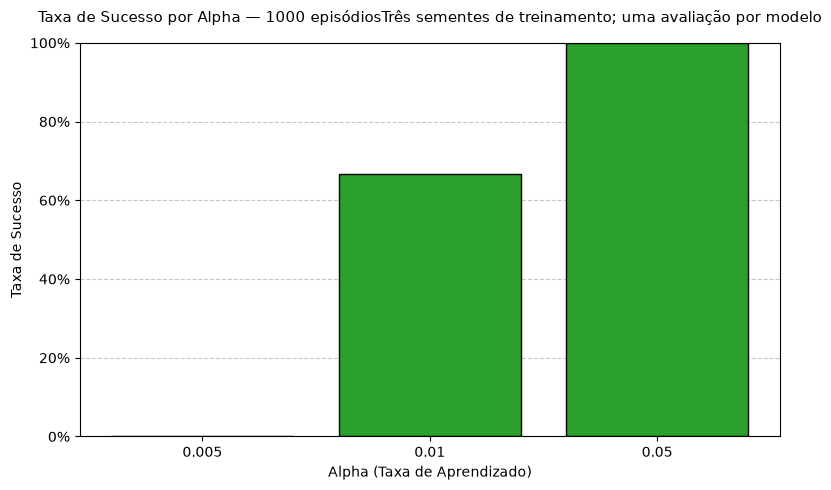


--- COMPARAÇÃO DOS EPISÓDIOS ---

--- RESULTADOS DOS EPISÓDIOS ---
 episodios  seed  alpha  pontuacao_acumulada  qtd_movimentos  chegou_saida
       100    42   0.01                 -150             150         False
       100    43   0.01                 -150             150         False
       100    44   0.01                 -150             150         False
       500    42   0.01                   17              14          True
       500    43   0.01                 -150             150         False
       500    44   0.01                   17              14          True
      1000    42   0.01                   17              14          True
      1000    43   0.01                 -150             150         False
      1000    44   0.01                   17              14          True

--- RESUMO DOS EPISÓDIOS ---
 episodios  taxa_sucesso  pontuacao_media  pontuacao_desvio  movimentos_medios  movimentos_desvio
       100      0.000000      -150.000000          0.0

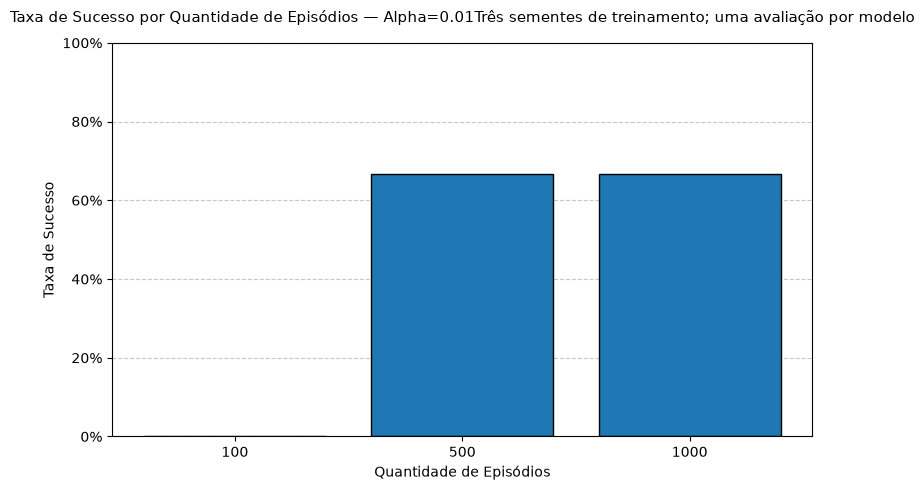


--- AVALIAÇÃO DO MODELO ILUSTRADO ---
Pontuação: 17
Movimentos: 14
Chegou à saída: True


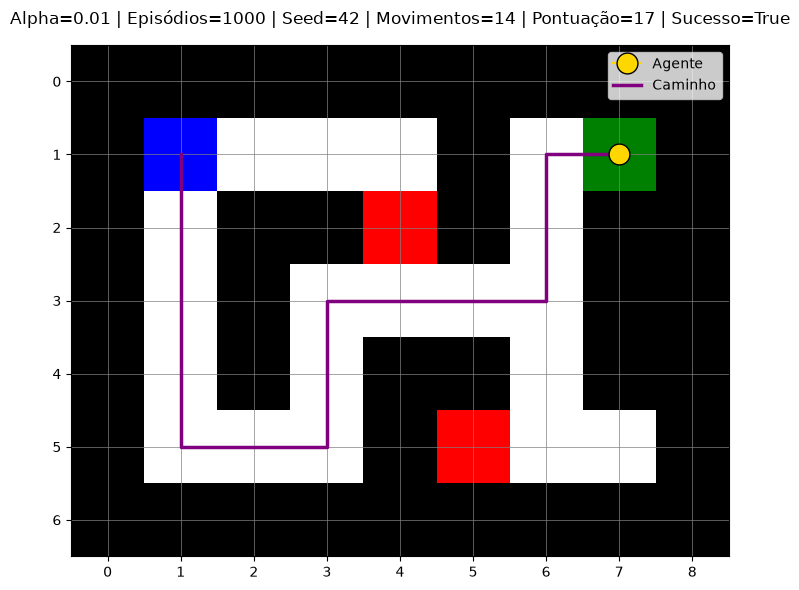

In [20]:
if __name__ == "__main__":

    mapa_labirinto = [
        ["#", "#", "#", "#", "#", "#", "#", "#", "#"],
        ["#", "S", ".", ".", ".", "#", ".", "E", "#"],
        ["#", ".", "#", "#", "T", "#", ".", "#", "#"],
        ["#", ".", "#", ".", ".", ".", ".", "#", "#"],
        ["#", ".", "#", ".", "#", "#", ".", "#", "#"],
        ["#", ".", ".", ".", "#", "T", ".", ".", "#"],
        ["#", "#", "#", "#", "#", "#", "#", "#", "#"]
    ]

    posicao_inicial = (1, 1)
    posicao_saida = (1, 7)
    posicao_armadilhas = [(2, 4), (5, 5)]

    valores_alpha = [0.005, 0.01, 0.05]
    seeds = [42, 43, 44]
    lista_episodios = [100, 500, 1000]
    qtd_episodios = 1000
    gama = 0.95
    epsilon = 0.3
    limite_movimentos = 150

    acoes_disponiveis = ["cima", "baixo", "direita", "esquerda"]


    # Comparação das taxas de aprendizado.
    print("--- INÍCIO DA COMPARAÇÃO DOS ALPHAS ---")

    resultados_alphas = comparar_alphas(valores_alpha, seeds, mapa_labirinto, gama, epsilon, acoes_disponiveis, limite_movimentos, posicao_inicial, posicao_saida, qtd_episodios)

    df_alphas = pd.DataFrame(resultados_alphas)
    df_resumo_alphas = resumir_resultados(df_alphas, "alpha")

    print("\n--- RESULTADOS DOS ALPHAS ---")
    print(df_alphas.to_string(index=False))

    print("\n--- RESUMO DOS ALPHAS ---")
    print(df_resumo_alphas.to_string(index=False))

    plotar_taxa_sucesso(df_resumo_alphas, "alpha", f"Taxa de Sucesso por Alpha — {qtd_episodios} episódios","Alpha (Taxa de Aprendizado)", "#2ca02c")

    # Comparação das quantidades de episódios.
    alpha_referencia = 0.01

    print("\n--- COMPARAÇÃO DOS EPISÓDIOS ---")

    resultados_episodios = comparar_episodios(lista_episodios, seeds, mapa_labirinto, alpha_referencia, gama, epsilon, acoes_disponiveis, limite_movimentos, posicao_inicial, posicao_saida)

    df_episodios = pd.DataFrame(resultados_episodios)
    df_resumo_episodios = resumir_resultados(df_episodios, "episodios")

    print("\n--- RESULTADOS DOS EPISÓDIOS ---")
    print(df_episodios.to_string(index=False))

    print("\n--- RESUMO DOS EPISÓDIOS ---")
    print(df_resumo_episodios.to_string(index=False))

    plotar_taxa_sucesso(df_resumo_episodios, "episodios", f"Taxa de Sucesso por Quantidade de Episódios — Alpha={alpha_referencia}", "Quantidade de Episódios", "#1f77b4")

    # Exemplo de percurso aprendido.
    ilustrar_modelo(mapa_labirinto, 0.01, gama, epsilon, acoes_disponiveis, limite_movimentos, posicao_inicial, posicao_saida, 42, 1000)


## Discussão dos resultados

### Influência da taxa de aprendizado

Com 1.000 episódios de treinamento, alpha = 0,005 não produziu modelos
capazes de alcançar a saída nas três sementes testadas. Todas as
avaliações atingiram 150 movimentos, com pontuação de -150.

Para alpha = 0,01, dois dos três modelos alcançaram a saída,
resultando em 66,7% de sucesso. Os modelos das sementes 42 e 44
concluíram o labirinto em 14 movimentos, com 17 pontos. O modelo
da semente 43 não chegou à saída antes do limite. Essa diferença
explica os desvios elevados da pontuação e da quantidade de movimentos.

Com alpha = 0,05, os três modelos chegaram à saída. A semente 42
produziu uma avaliação de 14 movimentos e 17 pontos, enquanto as
sementes 43 e 44 produziram avaliações de 10 movimentos e 12 pontos.

Esses resultados mostram que menos movimentos não significa
necessariamente maior pontuação, pois o percurso pode envolver
penalidades. O caminho ilustrado para alpha = 0,01 e semente 42
confirma uma rota de 14 movimentos que evita as armadilhas.

Entre os valores testados, alpha = 0,05 apresentou maior consistência
em alcançar a saída. Entretanto, isso não permite afirmar que essa
taxa seja superior em outros mapas ou configurações.

### Influência da quantidade de episódios

Mantendo alpha = 0,01, os modelos treinados por 100 episódios não
alcançaram a saída nas avaliações. Com 500 episódios, dois dos três
modelos concluíram o labirinto.

Com 1.000 episódios, a taxa de sucesso permaneceu em 66,7%, e as
médias e os desvios da pontuação e dos movimentos foram iguais
aos obtidos com 500 episódios.

Assim, aumentar de 100 para 500 episódios melhorou os resultados
nas condições testadas. O aumento de 500 para 1.000 episódios
não trouxe melhora nos indicadores finais apresentados. Isso não
significa que os pesos permaneceram iguais ou que o aprendizado
tenha convergido.

### Variação entre as sementes

Os resultados de alpha = 0,01 mostram que uma mesma configuração
pode produzir modelos com desempenhos diferentes conforme a semente
de treinamento. Isso ocorre porque as escolhas de exploração e os
desempates influenciam as experiências utilizadas no aprendizado.

Por esse motivo, foram considerados todos os resultados, incluindo
os casos em que o agente não alcançou a saída.

## Conclusão e limitações

Foi implementado um jogo de labirinto com caminhos alternativos
e armadilhas e um agente baseado em Q-learning com aproximação linear.
O agente utiliza 17 características e aprende seus pesos por meio
das recompensas recebidas durante a interação com o ambiente.

Os experimentos mostraram que a taxa de aprendizado e a quantidade
de episódios influenciaram o desempenho nas condições avaliadas.
Também foram observadas diferenças entre sementes, indicando que
uma execução bem-sucedida não garante o mesmo resultado em todos
os treinamentos.

Foi obtido um modelo capaz de alcançar a saída em 14 movimentos,
evitando as armadilhas e acumulando 17 pontos. Outros modelos
concluíram o jogo com pontuações diferentes ou não alcançaram
a saída antes do limite.

Como limitações, foram utilizados apenas um mapa fixo, uma posição
inicial fixa, três sementes de treinamento e uma avaliação por modelo.
Portanto, os resultados descrevem essas condições e não demonstram
generalização para novos labirintos, garantia de convergência ou
obtenção da melhor política possível.